Name : Bhalchim Roshani Ramchandra  
Roll No. : 08  
Title : Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. Perform following tasks:  
1. Pre-process the dataset.  
2. Identify outliers.  
3. Check the correlation.  
4. Implement linear regression and ridge, Lasso regression models.  
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.  
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset  

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("uber.csv")
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
print(df.head())
print(df.isnull().sum())

   fare_amount          pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1          7.7  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2         12.9  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3          5.3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4         16.0  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [4]:
df = df.dropna()
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)
df["hour"] = df["pickup_datetime"].dt.hour
df = df.drop(columns=["pickup_datetime"])

df = df[(df.fare_amount > 0) & (df.passenger_count.between(1, 6))]
df = df[df.pickup_latitude.between(-90, 90) & df.dropoff_latitude.between(-90, 90)]
df = df[df.pickup_longitude.between(-180, 180) & df.dropoff_longitude.between(-180, 180)]

print("Cleaned data:", df.shape)

Cleaned data: (199256, 7)


Outliers: 17120


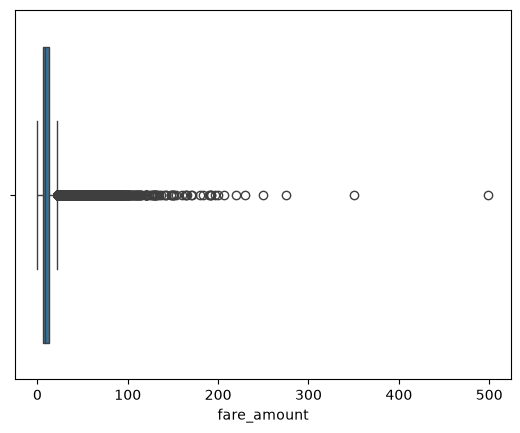

In [5]:
#Identify and remove outliers
Q1, Q3 = df.fare_amount.quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = df[~df.fare_amount.between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)]

print("Outliers:", len(outliers))
sns.boxplot(x=df.fare_amount)
plt.show()

df = df[df.fare_amount.between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)]

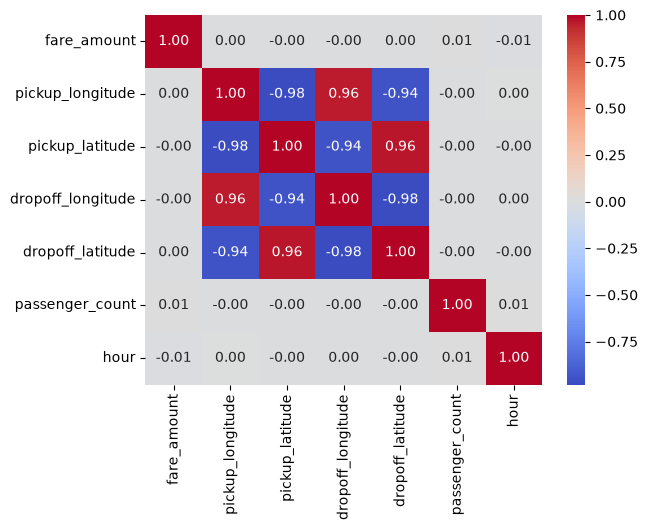

In [6]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [7]:
#Split data and scale features
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
Xs_train = scaler.fit_transform(X_train)
Xs_test = scaler.transform(X_test)

In [8]:
#train all regression model
lr = LinearRegression().fit(X_train, y_train)
ridge = Ridge().fit(Xs_train, y_train)
lasso = Lasso(max_iter=10000).fit(Xs_train, y_train)

predictions = [
    lr.predict(X_test),
    ridge.predict(Xs_test),
    lasso.predict(Xs_test)
]

In [9]:
#Evaluate and compare models
for name, pred in zip(["Linear", "Ridge", "Lasso"], predictions):
    print(name,
          "R2:", round(r2_score(y_test, pred), 3),
          "RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3),
          "MAE:", round(mean_absolute_error(y_test, pred), 3))

Linear R2: -0.0 RMSE: 4.125 MAE: 3.273
Ridge R2: -0.0 RMSE: 4.125 MAE: 3.273
Lasso R2: -0.0 RMSE: 4.125 MAE: 3.272


In [10]:
ride = pd.DataFrame([{
    "pickup_longitude": -73.99,
    "pickup_latitude": 40.75,
    "dropoff_longitude": -73.98,
    "dropoff_latitude": 40.76,
    "passenger_count": 1,
    "hour": 12
}])

print("Predicted Fare: $", round(max(0, lr.predict(ride)[0]), 2))

Predicted Fare: $ 8.93
